# CSCI447P016 Final Project

**Title:** Federated GRANDE: Heterogeneity, Calibration, and Structure-Aware Communication in Differentiable Tree Ensembles
**Course:** CSCI 447 Machine Learning: Theory and Practice
**Students:** Ayazhan Uzbekbay (202268516), Nuray Amanzholova (202184732)

This notebook implements the main methodology of the project and recomputes the reported evaluation from the saved outputs of the frozen experiments. Full source code and all saved runs: https://github.com/ayazhn04/csci447-fedgrande

## Imports

In [1]:
# import libraries
import json
import hashlib
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from pathlib import Path
from IPython.display import display
from scipy.io import arff
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    confusion_matrix as sk_confusion_matrix,
    precision_recall_fscore_support,
    accuracy_score,
    f1_score,
    roc_curve,roc_auc_score
)

# set plot style
plt.rcParams["font.family"]="DejaVu Sans"
plt.rcParams["font.size"]=10
plt.rcParams["figure.dpi"]=100
c="#772A8E"
cb="#F2A93B"
bg="#FBFAFE"
gr="#EBE4F2"
sp="#DCD2E8"
tx="#1A0F2B"
ct="#2A9D8F"
cg="#8C93A1"
co="#E0792A"

t_start=time.perf_counter()

## Configuration

In [2]:
# project seeds
model_seeds=[42,447,2026]
partition_seed=7
split_seed=42
np.random.seed(split_seed)
torch.manual_seed(split_seed)

# paths (everything is read from this folder)
data_file=Path("SpeedDating_openml40536_v1.arff")
art=Path("artifacts")

# main models of the core study
models=[
    ("central_grande","none","Centralized GRANDE"),
    ("fedavg_grande","natural","FedAvg GRANDE (nat.)"),
    ("fedavg_grande","iid","FedAvg GRANDE (IID)"),
    ("local_grande","natural","Local GRANDE (nat.)"),
    ("local_grande","iid","Local GRANDE (IID)"),
    ("central_mlp","none","Centralized MLP"),
    ("fedavg_mlp","natural","FedAvg MLP (nat.)"),
    ("fedavg_mlp","iid","FedAvg MLP (IID)")
]

print("model seeds:",model_seeds)
print("partition seed:",partition_seed)
print("outer split seed:",split_seed)

model seeds: [42, 447, 2026]
partition seed: 7
outer split seed: 42


The three model seeds are repeated runs on the same folds, not independent datasets, so no significance tests are reported.

## Dataset

SpeedDating (OpenML 40536, version 1) has one row per participant per speed date. The target `match` is 1 when both participants wanted to meet again.

In [3]:
# check dataset file
raw=data_file.read_bytes()
print("file size (bytes):",len(raw))
print("md5:",hashlib.md5(raw).hexdigest())
print("sha256:",hashlib.sha256(raw).hexdigest())
assert hashlib.md5(raw).hexdigest()=="0c5590a0c81750687ee1b0ee68168a5d"

file size (bytes): 4996633
md5: 0c5590a0c81750687ee1b0ee68168a5d
sha256: 121ad0ca93e82c21964709bdcea222119a362cfdd8f4c38d1f010bc830dda38a


In [4]:
# load arff with nominal columns as categories (arff-declared order)
def load_arff(path):
    data,meta=arff.loadarff(path)
    df=pd.DataFrame(data)
    for col in meta.names():
        kind,cats=meta[col]
        if kind=="nominal":
            v=df[col].str.decode("utf-8").replace("?",np.nan)
            df[col]=pd.Categorical(v,categories=list(cats))
    return df

full=load_arff(data_file)
y=full["match"].astype(str).astype(int).to_numpy()

print("dataset shape:",full.shape)
print("class counts [no match, match]:",np.bincount(y))
print("positive rate:",round(y.mean(),4))
print("missing values:",int(full.isna().sum().sum()))
assert full.shape[0]==8378 and np.bincount(y).tolist()==[6998,1380]

dataset shape: (8378, 123)
class counts [no match, match]: [6998 1380]
positive rate: 0.1647
missing values: 18372


In [5]:
# columns that are never model features
target="match"
label_proxies=["decision","decision_o"]
client_col="wave"

X=full.drop(columns=[target]+label_proxies+[client_col])
num_cols=[k for k in X.columns if not isinstance(X[k].dtype,pd.CategoricalDtype)]
cat_cols=[k for k in X.columns if isinstance(X[k].dtype,pd.CategoricalDtype)]
waves=full[client_col].astype(int).to_numpy()

print("openml predictors (without target and label proxies):",full.shape[1]-3)
print("modeled raw features:",X.shape[1])
print("numeric:",len(num_cols))
print("nominal:",len(cat_cols))
print("natural clients (waves):",len(np.unique(waves)))
assert X.shape[1]==119 and len(num_cols)==58 and len(cat_cols)==61

openml predictors (without target and label proxies): 120
modeled raw features: 119
numeric: 58
nominal: 61
natural clients (waves): 21


`decision` and `decision_o` together define the label, and `wave` identifies the client, so these columns are excluded. The model uses 119 raw features.

## Leakage Groups

Almost every date appears twice, once from each participant's side. The two rows mirror each other's partner columns and share the label, so a row-wise split puts one row of a date in training and its mirror in test. We join mirror rows into leakage groups (connected components of the mirror graph). This is a compact adaptation of `src/fedgrande/dyads.py`.

In [6]:
# self-side column, partner-side column
mirror_pairs=[
    ("age","age_o"),("race","race_o"),
    ("attractive_important","pref_o_attractive"),("sincere_important","pref_o_sincere"),
    ("intellicence_important","pref_o_intelligence"),("funny_important","pref_o_funny"),
    ("ambtition_important","pref_o_ambitious"),("shared_interests_important","pref_o_shared_interests"),
    ("attractive_partner","attractive_o"),("sincere_partner","sinsere_o"),
    ("intelligence_partner","intelligence_o"),("funny_partner","funny_o"),
    ("ambition_partner","ambitous_o"),("shared_interests_partner","shared_interests_o")
]
symmetric=["samerace","d_age","interests_correlate"]

# missing values are compared as their own token
def tokens(s):
    return np.array(["<NA>" if pd.isna(v) else repr(float(v)) if isinstance(v,(int,float,np.floating)) else str(v)
                     for v in s.astype(object)],dtype=object)

def leakage_groups(df):
    n=len(df)
    S=np.empty((n,len(mirror_pairs)),dtype=np.int64)
    P=np.empty_like(S)
    for k,(a,b) in enumerate(mirror_pairs):
        codes,_=pd.factorize(np.concatenate([tokens(df[a]),tokens(df[b])]))
        S[:,k],P[:,k]=codes[:n],codes[n:]
    Y=np.column_stack([pd.factorize(tokens(df[k]))[0] for k in symmetric])
    w=df["wave"].to_numpy()
    g=df["gender"].astype(str).to_numpy()

    # exact mirror candidates: j's self side equals i's partner side, same wave, opposite gender
    cand=[None]*n
    for v in np.unique(w):
        idx=np.flatnonzero(w==v)
        D=(P[idx][:,None,:]!=S[idx][None,:,:]).sum(-1)+(Y[idx][:,None,:]!=Y[idx][None,:,:]).sum(-1)
        D=np.where(g[idx][:,None]==g[idx][None,:],10**6,D)
        for a,i in enumerate(idx):
            cand[i]=idx[D[a]==0]

    # connected components, numbered by their smallest row index
    rows=np.concatenate([np.full(len(cand[i]),i) for i in range(n)])
    cols=np.concatenate(cand)
    A=coo_matrix((np.ones(len(rows)),(rows,cols)),shape=(n,n))
    _,lab=connected_components(A,directed=False)
    first=pd.Series(np.arange(n)).groupby(lab).min()
    gid=pd.Series(lab).map(pd.Series(np.argsort(np.argsort(first.to_numpy())),index=first.index)).to_numpy()

    kind=np.empty(n,dtype=object)
    mirror=np.full(n,-1)
    for d,members in pd.Series(np.arange(n)).groupby(gid):
        m=members.to_numpy()
        if len(m)==1:
            kind[m]="singleton"
        elif len(m)==2:
            i,j=m
            kind[m]="pair_mutual" if (j in cand[i] and i in cand[j]) else "pair_one_way"
            mirror[i],mirror[j]=j,i
        else:
            kind[m]="ambiguous_group"
    return gid,kind,mirror

In [7]:
# build leakage groups
gid,kind,mirror=leakage_groups(full)

gtab=pd.DataFrame({"group":gid,"kind":kind}).groupby("kind").agg(
    Groups=("group","nunique"),Rows=("group","size")
).loc[["pair_mutual","pair_one_way","ambiguous_group","singleton"]]
gtab.loc["Total"]=gtab.sum()
display(gtab)

# cross-check with the frozen project groups
frozen=pd.read_csv(art/"frozen_groups_and_splits.csv")
print("number of leakage groups:",len(np.unique(gid)))
print("same groups as frozen project file:",(gid==frozen.leakage_group_id.to_numpy()).all())
assert len(np.unique(gid))==4189
assert (gid==frozen.leakage_group_id.to_numpy()).all() and (kind==frozen.group_kind.to_numpy()).all()

,Groups,Rows
kind,,
pair_mutual,4173,8346
pair_one_way,2,4
ambiguous_group,4,18
singleton,10,10
Total,4189,8378


number of leakage groups: 4189
same groups as frozen project file: True


Only the 4,175 two-row groups are dyads. The 4 ambiguous groups and 10 singletons are leakage groups, not confirmed dyads.

## Evaluation Splits

In [8]:
# row-wise stratified 5-fold (the historical protocol)
def rowwise_folds(y,k=5,seed=split_seed):
    fold=np.full(len(y),-1)
    for f,(_,te) in enumerate(StratifiedKFold(k,shuffle=True,random_state=seed).split(np.zeros(len(y)),y)):
        fold[te]=f
    return fold

# group-level stratified 5-fold: a whole leakage group gets one fold
def grouped_folds(y,groups,k=5,seed=split_seed):
    uniq,inv=np.unique(groups,return_inverse=True)
    lab=np.zeros(len(uniq),dtype=int)
    np.maximum.at(lab,inv,y)
    gfold=np.full(len(uniq),-1)
    for f,(_,te) in enumerate(StratifiedKFold(k,shuffle=True,random_state=seed).split(np.zeros(len(uniq)),lab)):
        gfold[te]=f
    return gfold[inv]

# test rows whose mirror row is in the training folds
def mirror_leak(fold):
    has=mirror>=0
    return int(sum(((fold==f)&has&(fold[np.where(has,mirror,0)]!=f)).sum() for f in range(5)))

fold_row=rowwise_folds(y)
fold_grp=grouped_folds(y,gid)

leak=pd.DataFrame({
    "Split":["Row-wise 5-fold","Grouped 5-fold"],
    "Test rows with mirror in training":[mirror_leak(fold_row),mirror_leak(fold_grp)],
})
leak["Share"]=(leak["Test rows with mirror in training"]/len(y)).round(3)
display(leak)
assert leak.iloc[0,1]==6686 and leak.iloc[1,1]==0
assert (fold_grp==frozen.C2_dyad_fold.to_numpy()).all() and (fold_row==frozen.C1_rowwise_fold.to_numpy()).all()

,Split,Test rows with mirror in training,Share
0,Row-wise 5-fold,6686,0.798
1,Grouped 5-fold,0,0.000


With row-wise CV, 79.8% of the test rows have their mirror in training. The grouped split removes this completely. All results below use the grouped split.

### Method 1: Grouped 80/20 Train-Test Split

The first grouped fold (**Fold 1**; fold 0 in the code) is the hold-out test set. Inside its training part a second grouped split separates *fit* rows (gradient steps) from *validation* rows. Validation chooses the early-stopping checkpoint and the decision threshold; the test rows are used only once, for the final evaluation.

In [9]:
# holdout = fold 1 (index 0); inner validation = fold 0 of a grouped 5-fold on the training rows
te=np.flatnonzero(fold_grp==0)
tr=np.flatnonzero(fold_grp!=0)
inner=grouped_folds(y[tr],gid[tr])
fit=np.sort(tr[inner!=0])
val=np.sort(tr[inner==0])

role=np.full(len(y),"test",dtype=object)
role[fit]="fit"
role[val]="val"

print("training side:",len(tr),f"({len(tr)/len(y):.1%})")
print("fit rows:",len(fit))
print("validation rows:",len(val))
print("test rows:",len(te),f"({len(te)/len(y):.1%})")
print("groups shared between fit/val/test:",len(set(gid[fit])&set(gid[val]))+len(set(gid[tr])&set(gid[te])))
assert (len(tr),len(fit),len(val),len(te))==(6701,5361,1340,1677)
assert (role==frozen.fold1_role.to_numpy()).all()

training side: 6701 (80.0%)
fit rows: 5361
validation rows: 1340
test rows: 1677 (20.0%)
groups shared between fit/val/test: 0


### Method 2: Grouped 5-Fold Cross-Validation

Every leakage group belongs to exactly one fold. Each fold is the test set once, and every row is tested exactly once.

In [10]:
# fold summary
ftab=pd.DataFrame({
    "Fold":[f"Fold {f+1}" for f in range(5)],
    "Test rows":[int((fold_grp==f).sum()) for f in range(5)],
    "Positives":[int(y[fold_grp==f].sum()) for f in range(5)],
    "Positive rate":[round(y[fold_grp==f].mean(),4) for f in range(5)],
    "Groups crossing train/test":[len(set(gid[fold_grp==f])&set(gid[fold_grp!=f])) for f in range(5)]
})
display(ftab)
print("every row tested once:",np.bincount(fold_grp).sum()==len(y))
print("max |fold positive rate - overall|:",round(max(abs(y[fold_grp==f].mean()-y.mean()) for f in range(5)),5))

,Fold,Test rows,Positives,Positive rate,Groups crossing train/test
0,Fold 1,1677,276,0.1646,0
1,Fold 2,1675,276,0.1648,0
2,Fold 3,1681,276,0.1642,0
3,Fold 4,1676,276,0.1647,0
4,Fold 5,1669,276,0.1654,0


every row tested once: True
max |fold positive rate - overall|: 0.00065


## Federated-Safe Preprocessing

Preprocessing is fitted only on fit rows and never uses labels. Each client sends label-free statistics and the server combines them. For numeric column $j$ with $n_j$ non-missing values, sum $s_j$ and sum of squares $q_j$:

$$\mu_j=\frac{s_j}{n_j},\qquad \sigma_j=\sqrt{\frac{q_j}{n_j}-\mu_j^2},\qquad z=\frac{x-\mu_j}{\sigma_j}$$

Missing numeric values are imputed with $\mu_j$. Nominal columns are one-hot encoded with the training vocabulary; a MISSING column is added only if training rows contain missing values, and unseen values become an all-zero block. There is no target encoding.

In [11]:
# label-free statistics of one client
def client_stats(Xc):
    A=Xc[num_cols].to_numpy(dtype=np.float64)
    m=~np.isnan(A)
    A0=np.where(m,A,0.)
    counts={}
    for k in cat_cols:
        vc=Xc[k].astype(object).where(Xc[k].notna(),None)
        d={}
        for v in vc:
            key="__MISSING__" if v is None else str(v)
            d[key]=d.get(key,0)+1
        counts[k]=d
    return m.sum(0),A0.sum(0),(A0**2).sum(0),counts

# server-side aggregation
def aggregate(stats):
    n=np.sum([s[0] for s in stats],axis=0).astype(np.float64)
    s1=np.sum([s[1] for s in stats],axis=0)
    s2=np.sum([s[2] for s in stats],axis=0)
    mean=s1/n
    var=np.maximum(s2/n-mean**2,0.)
    sd=np.where(var<=1e-12,1.,np.sqrt(var))
    vocab,has_miss={},{}
    for k in cat_cols:
        tot={}
        for s in stats:
            for v,cnt in s[3][k].items():
                tot[v]=tot.get(v,0)+cnt
        vocab[k]=[str(v) for v in X[k].cat.categories if tot.get(str(v),0)>0]
        has_miss[k]=tot.get("__MISSING__",0)>0
    return mean,sd,vocab,has_miss

# encode rows with the aggregated parameters
def encode(Xp,mean,sd,vocab,has_miss):
    names=list(num_cols)
    for k in cat_cols:
        names+=[f"{k}={v}" for v in vocab[k]]+([f"{k}=__MISSING__"] if has_miss[k] else [])
    col_of={n:i for i,n in enumerate(names)}
    A=Xp[num_cols].to_numpy(dtype=np.float64)
    A=np.where(np.isnan(A),mean[None,:],A)
    Z=np.zeros((len(Xp),len(names)),dtype=np.float32)
    Z[:,:len(num_cols)]=((A-mean)/sd).astype(np.float32)
    for k in cat_cols:
        for r,v in enumerate(Xp[k].astype(object).to_numpy()):
            key=f"{k}=__MISSING__" if (v is None or (isinstance(v,float) and np.isnan(v))) else f"{k}={v}"
            if key in col_of:
                Z[r,col_of[key]]=1.
    return Z,names

In [12]:
# fit on fold 1 fit rows, one statistics message per natural client (wave)
stats=[client_stats(X.iloc[fit[waves[fit]==w]]) for w in np.unique(waves)]
mean,sd,vocab,has_miss=aggregate(stats)
Z,feat_names=encode(X,mean,sd,vocab,has_miss)

print("encoded features:",Z.shape[1])
print("numeric:",len(num_cols))
print("one-hot:",Z.shape[1]-len(num_cols))
print("missing columns:",[k for k in cat_cols if has_miss[k]])
print("fit-row numeric means after scaling (max |mean|):",round(float(np.abs(Z[fit,:len(num_cols)].mean(0)).max()),6))

# compare with the frozen encoded matrix used in the experiments
prov=json.load(open(art/"provenance.json"))
same=hashlib.sha256(np.ascontiguousarray(Z).tobytes()).hexdigest()==prov["fold1_encoded_matrix_sha256"]
print("identical to frozen experiment matrix:",same)
assert Z.shape[1]==502 and same

encoded features: 502
numeric: 58
one-hot: 444
missing columns: ['race', 'race_o', 'field']
fit-row numeric means after scaling (max |mean|): 2e-06
identical to frozen experiment matrix: True


Validation and test rows are only transformed, never used for fitting. The encoded matrix is bit-identical to the one used by the experiments.

## GRANDE Model

GRANDE is an ensemble of $E$ hard, axis-aligned trees of depth $d$ trained by gradient descent. Each tree $e$ gets $V$ candidate features. Node $i$ has feature logits $\iota_{e,i}$ and thresholds $\tau_{e,i}$; it tests the feature with the largest logit, $f_{e,i}$, with a softsign split rounded to a hard decision:

$$s(z)=\frac12\left(\frac{z}{1+|z|}+1\right),\qquad S_{e,i}(x)=\mathrm{round}\big(s(x_{f_{e,i}}-\tau_{e,i})\big)$$

The argmax and the rounding use straight-through gradients. A row reaches one leaf $l_e(x)$ per tree and the output is a weighted sum of leaf values $\lambda$:

$$G(x)=\sum_{e=1}^{E}\omega_e(x)\,\lambda_{e,l_e(x)},\qquad \omega_e(x)=\frac{\exp(W_{e,l_e(x)})}{\sum_{e'}\exp(W_{e',l_{e'}(x)})}$$

Training minimizes class-weighted cross-entropy with $w_c=(1/n_c)/\sum_j(1/n_j)$. We use $E=256$, $d=5$ (31 internal nodes, 32 leaves) and $V=50$.

In [13]:
# trainable tensors of the 256-tree model (from the saved gate-0 table)
tens=pd.read_csv(art/"grande_tensors.csv")
tens["role"]=["structure","structure","output","output"]
tens["name"]=["thresholds (split_values)","feature logits (split_index_array)",
              "tree weights (estimator_weights)","leaf values (leaf_classes_array)"]
display(tens[["name","role","shape","params","share_pct"]].round(2))

print("trainable parameters:",tens.params.sum())
print("structure share of payload (%):",round(tens[tens.role=="structure"].share_pct.sum(),2))
assert tens.params.sum()==809984

,name,role,shape,params,share_pct
0,thresholds (split_values),structure,256x31x50,396800,48.99
1,feature logits (split_index_array),structure,256x31x50,396800,48.99
2,tree weights (estimator_weights),output,256x32,8192,1.01
3,leaf values (leaf_classes_array),output,256x32,8192,1.01


trainable parameters: 809984
structure share of payload (%): 97.98


## Federated Training

In round $r$ every client $k$ loads the global parameters, trains one local epoch on its $n_k$ fit rows with a fresh Adam optimizer, and sends the parameters back. The server takes the weighted average

$$\theta^{(r+1)}=\sum_{k=1}^{K}\frac{n_k}{\sum_j n_j}\,\theta_k^{(r)},\qquad K=21$$

The candidate-feature buffer is shared and never averaged, so a logit position means the same feature on every client. The global model is validated after every round and the best state is restored.

The complete training matrices are already frozen in the project repository. The notebook shows the implementation and recomputes the reported evaluation from the saved predictions so that it can be executed in minutes rather than rerunning approximately 21 CPU-hours of experiments.

In [14]:
# per-group learning rates of grande 1.0
lr_grande={"split_values":.01,"split_index_array":.01,"estimator_weights":.005,"leaf_classes_array":.01}

# fresh local adam over the active tensors
def make_adam(model,active):
    return torch.optim.Adam([
        {"params":getattr(model,k),"lr":lr_grande[k],"betas":(.9,.95)} for k in active
    ])

# one local epoch with batch size min(256, n//2)
def local_epoch(model,opt,Xc,yc,w,gen):
    n=len(Xc)
    bs=max(1,min(256,n//2))
    perm=torch.randperm(n,generator=gen)
    model.train()
    for s in range(0,n-bs+1,bs):
        idx=perm[s:s+bs]
        loss=F.cross_entropy(model(Xc[idx]),yc[idx],weight=w)
        opt.zero_grad()
        loss.backward()
        opt.step()

# row-count-weighted average of client tensors
def fedavg_aggregate(states,n_rows):
    wn=np.asarray(n_rows,dtype=np.float64)/np.sum(n_rows)
    return {k:sum(float(wn[i])*states[i][k] for i in range(len(states))) for k in states[0]}

# class-weighted validation auc of the global model
@torch.no_grad()
def val_auc(model,Xv,yv):
    model.eval()
    p=F.softmax(model(Xv),-1)[:,1].numpy()
    return roc_auc_score(yv,p)

# fedavg with local adam, early stopping on validation auc (patience 10, warm-up 10, min_delta 1e-4)
def fedavg(build_model,clients,Xv,yv,w,seed,rounds=100,patience=10,warmup=10,gate=None):
    glob=build_model(seed)
    local=build_model(seed)
    active=list(lr_grande)
    n_rows=[len(Xc) for Xc,_ in clients]
    best,best_r,best_state=None,None,None
    for r in range(1,rounds+1):
        states,sels=[],[]
        for k,(Xc,yc) in enumerate(clients):
            local.load_state_dict(glob.state_dict())             # send global state
            for name,p in local.named_parameters():
                p.requires_grad_(name in active)
            opt=make_adam(local,active)                          # reset local adam
            gen=torch.Generator().manual_seed(seed*1_000_003+r*1_000+k)
            local_epoch(local,opt,Xc,yc,w,gen)                   # one local epoch
            states.append({k2:getattr(local,k2).detach().clone() for k2 in active})
            sels.append(selected_features(local))
        new=fedavg_aggregate(states,n_rows)                      # weighted fedavg of active tensors
        with torch.no_grad():
            for k2,v in new.items():
                getattr(glob,k2).copy_(v)
        if gate is not None and gate.update(r,np.stack(sels)):   # consensus gate (G1)
            active=["leaf_classes_array","estimator_weights"]    # freeze feature logits and thresholds
        auc=val_auc(glob,Xv,yv)                                  # validate global model
        if best is None or auc>best+1e-4:
            best,best_r,best_state=auc,r,copy.deepcopy(glob.state_dict())
        if r>=warmup and r-best_r>=patience:
            break
    glob.load_state_dict(best_state)                             # restore best validation state
    return glob,best_r

### Consensus-Gated Freezing (G1)

After local training we record the feature $f_{k,j}$ that client $k$ selects at node $j$. Node consensus is the share of clients choosing the most common feature; over the $J=7{,}936$ internal nodes we track the mean and the unanimous fraction:

$$C_j=\frac1K\max_f\big|\{k:f_{k,j}=f\}\big|,\qquad C_{\text{mean}}=\frac1J\sum_j C_j,\qquad U=\frac1J\sum_j \mathbf 1[C_j=1]$$

With warm-up 10, the gate fires after the first round $r^*\ge13$ where $C_{\text{mean}}\ge0.98$ and $U\ge0.85$ held for 3 consecutive rounds. From round $r^*+1$ the feature logits and thresholds are frozen and only leaves and tree weights are federated.

In [15]:
# selected original feature per internal node: features_by_estimator[e, argmax logits]
def selected_features(model):
    idx=model.split_index_array.detach().argmax(-1)
    return torch.gather(model.features_by_estimator,1,idx).numpy()

# share of clients choosing the modal feature at every node
def node_consensus(Fk):
    same=(Fk[:,None]==Fk[None,:]).sum(1)
    return same.max(0)/Fk.shape[0]

# global gate: warm-up 10, mean >= 0.98 and unanimous >= 0.85 for 3 rounds
class GlobalGate:
    def __init__(self,warmup=10,c_mean=.98,c_unan=.85,consecutive=3):
        self.warmup,self.c_mean,self.c_unan,self.consecutive=warmup,c_mean,c_unan,consecutive
        self.streak,self.trigger=0,None

    def check(self,r,cmean,unan):
        if self.trigger is not None or r<=self.warmup:
            return False
        self.streak=self.streak+1 if (cmean>=self.c_mean and unan>=self.c_unan) else 0
        if self.streak>=self.consecutive:
            self.trigger=r
            return True
        return False

    def update(self,r,Fk):
        Cj=node_consensus(Fk)
        return self.check(r,Cj.mean(),(Cj==1).mean())

In [16]:
# replay the gate on the saved per-round consensus logs of the 30 G1 runs
logs=pd.read_csv(art/"g1_round_logs.csv")
saved=pd.read_csv(art/"g1_trigger_rounds.csv")

trig=[]
for (p,f,s),g in logs.groupby(["partition","fold","seed"]):
    gate=GlobalGate()
    for row in g.itertuples():
        gate.check(row.round,row.cons_mean,row.cons_unanimous)
    trig.append([p,f,s,gate.trigger])
trig=pd.DataFrame(trig,columns=["partition","fold","seed","replayed"]).merge(saved,on=["partition","fold","seed"])

print("runs:",len(trig))
print("replayed trigger = saved trigger:",(trig.replayed==trig.trigger_round).all())
print("trigger round mean ± sd:",round(trig.replayed.mean(),1),"±",round(trig.replayed.std(),1))
assert (trig.replayed==trig.trigger_round).all()

runs: 30
replayed trigger = saved trigger: True
trigger round mean ± sd: 20.4 ± 1.4


The gate code reproduces the trigger round of every saved G1 run from its logged consensus values.

## Metrics

With $TP,TN,FP,FN$ from the confusion matrix and $N$ rows:

$$\text{Accuracy}=\frac{TP+TN}{N},\quad \text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN},\quad F_1=\frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

$\text{AUC}=P[p(x^+)>p(x^-)]$ does not depend on the threshold. **F1-score** in the tables is the positive-class F1. **Macro-F1** (mean of the F1 of both classes) is used separately: it selects the decision threshold on validation rows and appears in some federated analyses.

In [17]:
# calculate binary confusion matrix
def confusion_matrix(y_true,y_pred):
    cm=np.zeros((2,2),dtype=int)
    np.add.at(cm,(np.asarray(y_true,dtype=int),np.asarray(y_pred,dtype=int)),1)
    return cm

# divide safely
def safe_div(a,b):
    return 0. if b==0 else a/b

# calculate required metrics at a threshold
def binary_metrics(y_true,p,thr):
    cm=confusion_matrix(y_true,(p>=thr).astype(int))
    tn,fp=cm[0]
    fn,tp=cm[1]
    pre=safe_div(tp,tp+fp)
    rec=safe_div(tp,tp+fn)
    f1=safe_div(2*pre*rec,pre+rec)
    f1_neg=safe_div(2*tn,2*tn+fn+fp)
    return {
        "TN":tn,"FP":fp,"FN":fn,"TP":tp,
        "Accuracy":safe_div(tp+tn,cm.sum()),"Precision":pre,"Recall":rec,
        "F1":f1,"Macro-F1":(f1+f1_neg)/2,"AUC":roc_auc_score(y_true,p)
    }

In [18]:
# cross-check metrics with sklearn
yb=np.array([1,1,1,1,0,0,0,0,0,0])
pb=np.array([.9,.4,.8,.3,.2,.1,.7,.35,.05,.6])
rb=binary_metrics(yb,pb,.5)
hb=(pb>=.5).astype(int)
cm_b=sk_confusion_matrix(yb,hb,labels=[0,1])
sk_pre,sk_rec,sk_f1,_=precision_recall_fscore_support(yb,hb,average="binary",zero_division=0)

sk_b={
    "TN":cm_b[0,0],"FP":cm_b[0,1],"FN":cm_b[1,0],"TP":cm_b[1,1],
    "Accuracy":accuracy_score(yb,hb),"Precision":sk_pre,"Recall":sk_rec,"F1":sk_f1,
    "Macro-F1":f1_score(yb,hb,average="macro"),"AUC":roc_auc_score(yb,pb)
}
check=pd.DataFrame({"Manual":[rb[k] for k in rb],"Sklearn":[sk_b[k] for k in rb]},index=list(rb))
check["Difference"]=np.abs(check["Manual"]-check["Sklearn"])
display(check)
print("max difference:",check["Difference"].max())
assert check["Difference"].max()<1e-12

,Manual,Sklearn,Difference
TN,4.000000,4.000000,0.0
FP,2.000000,2.000000,0.0
FN,2.000000,2.000000,0.0
TP,2.000000,2.000000,0.0
Accuracy,0.600000,0.600000,0.0
Precision,0.500000,0.500000,0.0
Recall,0.500000,0.500000,0.0
F1,0.500000,0.500000,0.0
Macro-F1,0.583333,0.583333,0.0
AUC,0.791667,0.791667,0.0


max difference: 0.0


## Saved Predictions

The saved predictions contain the test rows of every fold and the validation rows of Fold 1 for all 8 models and 3 seeds (120 runs). Each run's validation-selected threshold is stored with it.

In [19]:
# load saved predictions and run information
pred=pd.read_csv(art/"core_predictions.csv")
runs=pd.read_csv(art/"core_run_info.csv")

def col(m,p,s):
    return f"{m}_{'central' if p=='none' else p}_s{s}"

def run_row(m,p,f,s):
    return runs[(runs.method==m)&(runs.partition==p)&(runs.fold==f)&(runs.seed==s)].iloc[0]

print("prediction table:",pred.shape)
print("runs:",len(runs))

prediction table: (9718, 28)
runs: 120


In [20]:
# validation threshold: maximize validation macro-F1 on 0.05..0.95, ties closest to 0.5
grid=np.round(np.arange(.05,.951,.01),2)

def select_threshold(yv,pv):
    scores=np.array([f1_score(yv,(pv>=t).astype(int),average="macro",zero_division=0) for t in grid])
    best=np.flatnonzero(scores==scores.max())
    return float(grid[best[np.argmin(np.abs(grid[best]-.5))]])

# recompute the fold 1 thresholds from validation rows only
v=pred[(pred.fold==0)&(pred.role=="val")]
match=[]
for m,p,_ in models:
    for s in model_seeds:
        match.append(select_threshold(v.y.to_numpy(),v[col(m,p,s)].to_numpy())==run_row(m,p,0,s).val_threshold)
print("recomputed thresholds equal saved thresholds:",np.sum(match),"of",len(match))
assert all(match)

recomputed thresholds equal saved thresholds: 24 of 24


## Hold-Out Results (Fold 1)

Threshold-dependent metrics use each run's validation-selected threshold. Values are the mean over the three seeds.

In [21]:
# metrics of every run on its test fold
rows=[]
for m,p,name in models:
    for f in range(5):
        t=pred[(pred.fold==f)&(pred.role=="test")]
        for s in model_seeds:
            r=run_row(m,p,f,s)
            res=binary_metrics(t.y.to_numpy(),t[col(m,p,s)].to_numpy(),r.val_threshold)
            assert [res["TN"],res["FP"],res["FN"],res["TP"]]==[r.saved_tn,r.saved_fp,r.saved_fn,r.saved_tp]
            rows.append({"Model":name,"Fold":f+1,"Seed":s,**res})
R=pd.DataFrame(rows)
print("runs evaluated:",len(R),"(all confusion matrices equal the saved runs)")

metric_cols=["Accuracy","Precision","Recall","F1","AUC"]
order=[n for _,_,n in models]
holdout=R[R.Fold==1].groupby("Model")[metric_cols].mean().loc[order]
display(holdout.round(3))

runs evaluated: 120 (all confusion matrices equal the saved runs)


,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
Centralized GRANDE,0.850,0.546,0.626,0.573,0.884
FedAvg GRANDE (nat.),0.858,0.580,0.508,0.541,0.882
FedAvg GRANDE (IID),0.858,0.579,0.502,0.537,0.883
Local GRANDE (nat.),0.788,0.364,0.357,0.355,0.717
Local GRANDE (IID),0.802,0.393,0.388,0.388,0.742
Centralized MLP,0.851,0.541,0.643,0.587,0.879
FedAvg MLP (nat.),0.853,0.558,0.583,0.566,0.875
FedAvg MLP (IID),0.850,0.540,0.615,0.573,0.876


In [22]:
# anchor check against report table vii
table7={
    "Centralized GRANDE":[.850,.546,.626,.573,.884],"FedAvg GRANDE (nat.)":[.858,.580,.508,.541,.882],
    "FedAvg GRANDE (IID)":[.858,.579,.502,.537,.883],"Local GRANDE (nat.)":[.788,.364,.357,.355,.717],
    "Local GRANDE (IID)":[.802,.393,.388,.388,.742],"Centralized MLP":[.851,.541,.643,.587,.879],
    "FedAvg MLP (nat.)":[.853,.558,.583,.566,.875],"FedAvg MLP (IID)":[.850,.540,.615,.573,.876]
}
diff=np.abs(holdout.round(3).to_numpy()-np.array([table7[k] for k in order])).max()
print("max difference to report table vii:",round(diff,4))
assert diff<.0015

max difference to report table vii: 0.0


FedAvg GRANDE reaches almost the same AUC as centralized GRANDE on Fold 1 but chooses a more conservative threshold (higher precision, lower recall). Local-only training is much worse.

## 5-Fold Cross-Validation

For every fold we first average the three seeds, giving $m_k$. Then we report the mean and the sample standard deviation over the five folds:

$$\mu_m=\frac15\sum_{k=1}^5 m_k,\qquad \sigma_m=\sqrt{\frac14\sum_{k=1}^5(m_k-\mu_m)^2}$$

In [23]:
# mean over seeds inside each fold, then mean and sd over folds
per_fold=R.groupby(["Model","Fold"])[metric_cols+["Macro-F1"]].mean()
cv_mean=per_fold.groupby("Model").mean().loc[order]
cv_sd=per_fold.groupby("Model").std(ddof=1).loc[order]

cv=pd.DataFrame(index=order)
for k in metric_cols:
    cv[k]=[f"{a:.3f} ± {b:.3f}" for a,b in zip(cv_mean[k],cv_sd[k])]
display(cv)

,Accuracy,Precision,Recall,F1,AUC
Centralized GRANDE,0.833 ± 0.014,0.500 ± 0.035,0.618 ± 0.046,0.548 ± 0.026,0.858 ± 0.017
FedAvg GRANDE (nat.),0.823 ± 0.022,0.481 ± 0.058,0.579 ± 0.069,0.519 ± 0.019,0.845 ± 0.022
FedAvg GRANDE (IID),0.821 ± 0.026,0.478 ± 0.060,0.574 ± 0.082,0.514 ± 0.018,0.846 ± 0.021
Local GRANDE (nat.),0.796 ± 0.006,0.393 ± 0.023,0.400 ± 0.045,0.389 ± 0.033,0.743 ± 0.017
Local GRANDE (IID),0.793 ± 0.006,0.383 ± 0.014,0.418 ± 0.047,0.395 ± 0.026,0.739 ± 0.014
Centralized MLP,0.831 ± 0.014,0.493 ± 0.032,0.614 ± 0.061,0.544 ± 0.031,0.853 ± 0.018
FedAvg MLP (nat.),0.832 ± 0.017,0.497 ± 0.045,0.598 ± 0.034,0.541 ± 0.031,0.851 ± 0.017
FedAvg MLP (IID),0.831 ± 0.019,0.493 ± 0.044,0.590 ± 0.047,0.534 ± 0.027,0.849 ± 0.016


In [24]:
# auc per fold
auc_fold=per_fold["AUC"].unstack().loc[order]
auc_fold.columns=[f"Fold {k}" for k in auc_fold.columns]
auc_fold["Mean"]=auc_fold.mean(1)
auc_fold["SD"]=auc_fold.iloc[:,:5].std(1,ddof=1)
display(auc_fold.round(3))

# anchor check against report tables viii and ix
assert abs(cv_mean.loc["FedAvg GRANDE (nat.)","AUC"]-.845)<.0005 and abs(cv_sd.loc["FedAvg GRANDE (nat.)","AUC"]-.022)<.0005
assert abs(cv_mean.loc["Centralized GRANDE","AUC"]-.858)<.0005 and abs(cv_mean.loc["Local GRANDE (nat.)","AUC"]-.743)<.0005
assert abs(cv_mean.loc["FedAvg MLP (nat.)","AUC"]-.851)<.0005

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,SD
Model,,,,,,,
Centralized GRANDE,0.884,0.864,0.855,0.844,0.842,0.858,0.017
FedAvg GRANDE (nat.),0.882,0.838,0.837,0.840,0.826,0.845,0.022
FedAvg GRANDE (IID),0.883,0.839,0.838,0.841,0.827,0.846,0.021
Local GRANDE (nat.),0.717,0.764,0.753,0.739,0.743,0.743,0.017
Local GRANDE (IID),0.742,0.737,0.760,0.734,0.722,0.739,0.014
Centralized MLP,0.879,0.862,0.850,0.836,0.836,0.853,0.018
FedAvg MLP (nat.),0.875,0.847,0.860,0.835,0.837,0.851,0.017
FedAvg MLP (IID),0.876,0.847,0.848,0.839,0.835,0.849,0.016


In [25]:
# pooled out-of-fold auc: pool the five test folds of one seed, then mean ± sd over seeds
t=pred[pred.role=="test"]
pool=[]
for m,p,name in models:
    a=[roc_auc_score(t.y,t[col(m,p,s)]) for s in model_seeds]
    pool.append([name,np.mean(a),np.std(a,ddof=1)])
pool=pd.DataFrame(pool,columns=["Model","Pooled AUC","SD over seeds"]).set_index("Model")
display(pool.round(4))
assert abs(pool.loc["FedAvg GRANDE (nat.)","Pooled AUC"]-.8438)<.00005

,Pooled AUC,SD over seeds
Model,,
Centralized GRANDE,0.8567,0.0009
FedAvg GRANDE (nat.),0.8438,0.0009
FedAvg GRANDE (IID),0.8446,0.0005
Local GRANDE (nat.),0.7408,0.0119
Local GRANDE (IID),0.7371,0.0049
Centralized MLP,0.8479,0.0046
FedAvg MLP (nat.),0.8501,0.0013
FedAvg MLP (IID),0.8472,0.0024


FedAvg GRANDE keeps 98.5% of the centralized AUC and is about 0.10 better than local-only training. Natural and IID clients give almost the same result. The pooled view agrees with the per-fold view; its SD is over seeds and is much smaller than the variation between folds.

### Performance Comparison

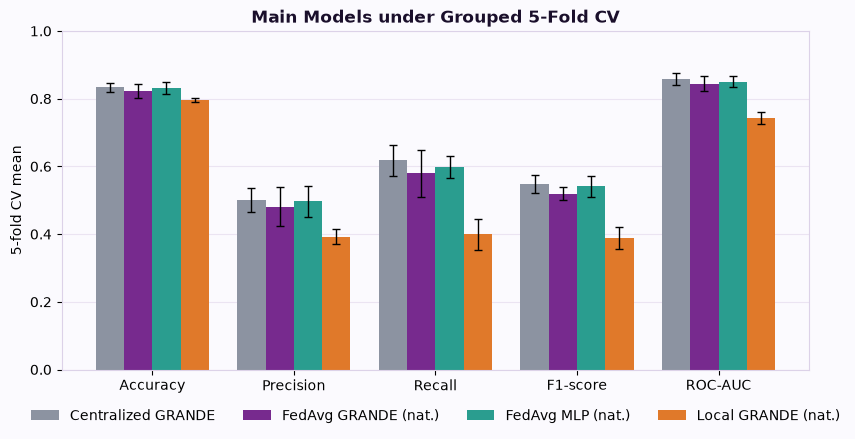

In [26]:
# plot 5-fold cv metrics of the main models
main=["Centralized GRANDE","FedAvg GRANDE (nat.)","FedAvg MLP (nat.)","Local GRANDE (nat.)"]
colors=[cg,c,ct,co]
x=np.arange(len(metric_cols))
wd=.2

plt.figure(figsize=(9,4.5),facecolor=bg)
ax=plt.gca()
ax.set_facecolor(bg)
for i,(name,cl) in enumerate(zip(main,colors)):
    ax.bar(x+(i-1.5)*wd,cv_mean.loc[name,metric_cols],wd,yerr=cv_sd.loc[name,metric_cols],
           color=cl,capsize=3,label=name,error_kw={"lw":1})
ax.set_xticks(x,["Accuracy","Precision","Recall","F1-score","ROC-AUC"])
ax.set_ylim(0,1)
ax.set_ylabel("5-fold CV mean")
ax.set_title("Main Models under Grouped 5-Fold CV",fontweight="bold",color=tx)
ax.grid(axis="y",color=gr,lw=.8)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_color(sp)
plt.legend(frameon=False,ncol=4,loc="upper center",bbox_to_anchor=(.5,-.08))
plt.tight_layout()
plt.show()

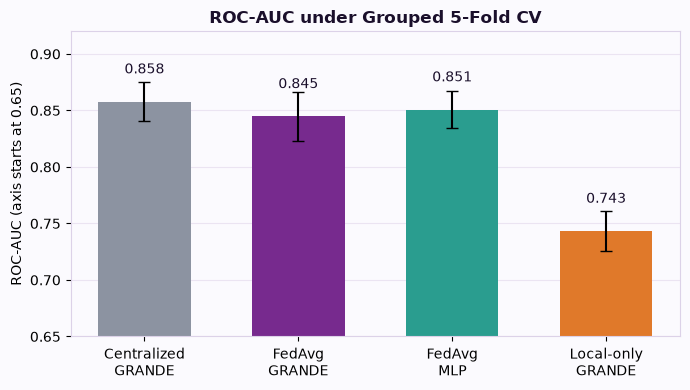

In [27]:
# zoom on roc-auc (y-axis does not start at zero)
plt.figure(figsize=(7,4),facecolor=bg)
ax=plt.gca()
ax.set_facecolor(bg)
vals=cv_mean.loc[main,"AUC"]
ax.bar(np.arange(4),vals,yerr=cv_sd.loc[main,"AUC"],color=colors,capsize=4,width=.6)
for i,v in enumerate(vals):
    ax.text(i,v+.025,f"{v:.3f}",ha="center",color=tx)
ax.set_xticks(np.arange(4),["Centralized\nGRANDE","FedAvg\nGRANDE","FedAvg\nMLP","Local-only\nGRANDE"])
ax.set_ylim(.65,.92)
ax.set_ylabel("ROC-AUC (axis starts at 0.65)")
ax.set_title("ROC-AUC under Grouped 5-Fold CV",fontweight="bold",color=tx)
ax.grid(axis="y",color=gr,lw=.8)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_color(sp)
plt.tight_layout()
plt.show()

## Training Curves

Hold-out fold, seed 42. The jobs logged the class-weighted loss and the validation ROC-AUC after every epoch or round; per-round accuracy was not logged.

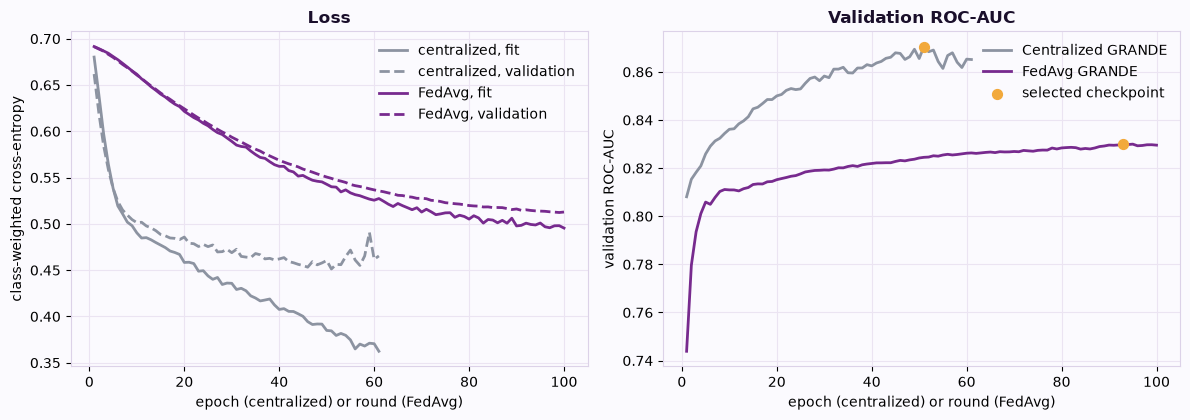

centralized: selected epoch 51 of 61
FedAvg: raw maximum validation auc at round 95 | selected round 93 of 100
auc gain after the selected round: 3.6e-05


In [28]:
# load saved curves
curves=pd.read_csv(art/"holdout_training_curves.csv")
cen=curves[curves.model=="Centralized GRANDE"]
fed=curves[curves.model=="FedAvg GRANDE"]

fig,ax=plt.subplots(1,2,figsize=(12,4.3),facecolor=bg)
for a in ax:
    a.set_facecolor(bg)

# plot loss
ax[0].plot(cen.step,cen.train_loss,color=cg,lw=2,label="centralized, fit")
ax[0].plot(cen.step,cen.val_loss,color=cg,lw=2,ls="--",label="centralized, validation")
ax[0].plot(fed.step,fed.train_loss,color=c,lw=2,label="FedAvg, fit")
ax[0].plot(fed.step,fed.val_loss,color=c,lw=2,ls="--",label="FedAvg, validation")
ax[0].set_xlabel("epoch (centralized) or round (FedAvg)")
ax[0].set_ylabel("class-weighted cross-entropy")
ax[0].set_title("Loss",fontweight="bold",color=tx)

# plot validation auc
r_cen=run_row("central_grande","none",0,42)
r_fed=run_row("fedavg_grande","natural",0,42)
ax[1].plot(cen.step,cen.val_auc,color=cg,lw=2,label="Centralized GRANDE")
ax[1].plot(fed.step,fed.val_auc,color=c,lw=2,label="FedAvg GRANDE")
ax[1].scatter(r_cen.best_step,cen.val_auc[cen.step==r_cen.best_step],s=50,color=cb,zorder=3,label="selected checkpoint")
ax[1].scatter(r_fed.best_step,fed.val_auc[fed.step==r_fed.best_step],s=50,color=cb,zorder=3)
ax[1].set_xlabel("epoch (centralized) or round (FedAvg)")
ax[1].set_ylabel("validation ROC-AUC")
ax[1].set_title("Validation ROC-AUC",fontweight="bold",color=tx)

for a in ax:
    a.grid(color=gr,lw=.8)
    for s in a.spines.values():
        s.set_color(sp)
    a.legend(frameon=False)
plt.tight_layout()
plt.show()

raw_best=int(fed.step.iloc[fed.val_auc.argmax()])
print("centralized: selected epoch",int(r_cen.best_step),"of",int(r_cen.steps_executed))
print("FedAvg: raw maximum validation auc at round",raw_best,"| selected round",int(r_fed.best_step),"of",int(r_fed.steps_executed))
print("auc gain after the selected round:",round(fed.val_auc.max()-fed.val_auc[fed.step==r_fed.best_step].iloc[0],6))

Centralized training overfits after a few dozen epochs and early stopping restores epoch 51. FedAvg improves slowly until the 100-round budget. Its raw maximum is at round 95, but the selected checkpoint is round 93 because a new best must improve by more than $10^{-4}$.

## Confusion Matrix

Centralized GRANDE threshold: 0.62 matrix: [[1210, 191], [69, 207]]
FedAvg GRANDE threshold: 0.72 matrix: [[1309, 92], [140, 136]]


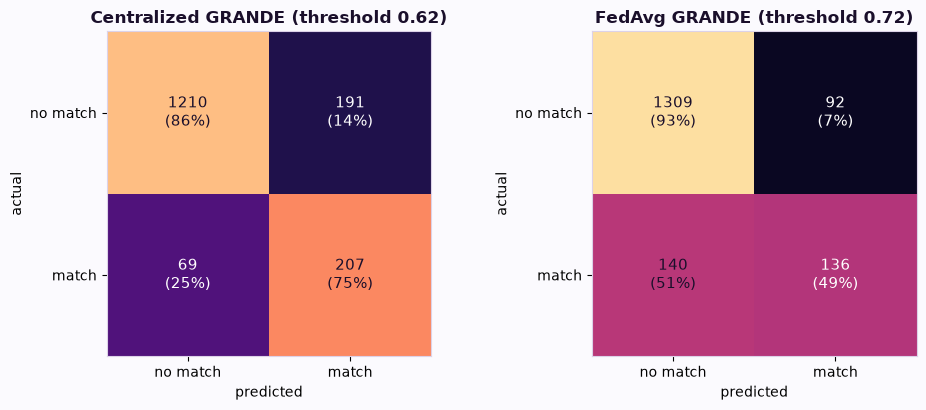

In [29]:
# confusion matrices on the hold-out fold, seed 42, validation threshold
t=pred[(pred.fold==0)&(pred.role=="test")]
cms={}
for m,p,name in [("central_grande","none","Centralized GRANDE"),("fedavg_grande","natural","FedAvg GRANDE")]:
    r=run_row(m,p,0,42)
    cms[name]=(confusion_matrix(t.y,(t[col(m,p,42)]>=r.val_threshold).astype(int)),r.val_threshold)
    print(name,"threshold:",r.val_threshold,"matrix:",cms[name][0].tolist())

assert cms["FedAvg GRANDE"][0].tolist()==[[1309,92],[140,136]] and cms["FedAvg GRANDE"][1]==.72

# plot counts and row percentages
fig,ax=plt.subplots(1,2,figsize=(10,4.2),facecolor=bg)
for a,(name,(cm,thr)) in zip(ax,cms.items()):
    a.set_facecolor(bg)
    pct=cm/cm.sum(1,keepdims=True)
    a.imshow(pct,cmap="magma",vmin=0,vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j,i,f"{cm[i,j]}\n({100*pct[i,j]:.0f}%)",ha="center",va="center",
                   color=tx if pct[i,j]>.5 else "white",fontsize=11)
    a.set_xticks([0,1],["no match","match"])
    a.set_yticks([0,1],["no match","match"])
    a.set_xlabel("predicted")
    a.set_ylabel("actual")
    a.set_title(f"{name} (threshold {thr:.2f})",fontweight="bold",color=tx)
    for s in a.spines.values():
        s.set_color(sp)
plt.tight_layout()
plt.show()

At its validation threshold FedAvg GRANDE finds 136 of the 276 matches and wrongly flags 92 of the 1,401 non-matches. The centralized model uses a lower threshold and finds more matches with more false alarms.

## ROC Curves

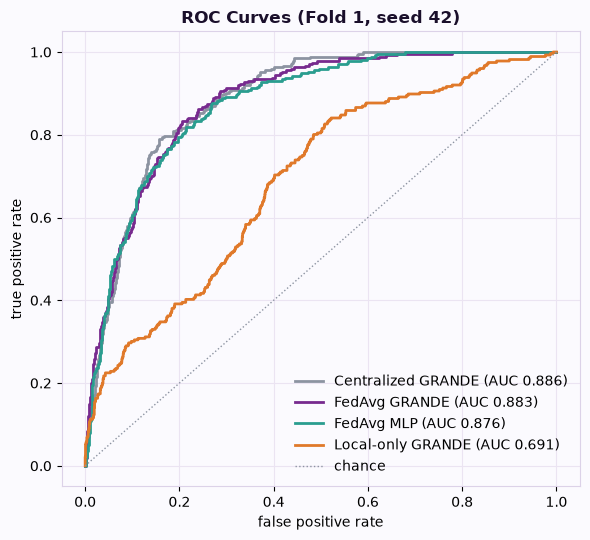

{'Centralized GRANDE': 0.886, 'FedAvg GRANDE': 0.883, 'FedAvg MLP': 0.876, 'Local-only GRANDE': 0.691}


In [30]:
# roc curves on the hold-out fold, seed 42
plt.figure(figsize=(6,5.5),facecolor=bg)
ax=plt.gca()
ax.set_facecolor(bg)
roc_auc={}
for (m,p,name),cl in zip([("central_grande","none","Centralized GRANDE"),("fedavg_grande","natural","FedAvg GRANDE"),
                          ("fedavg_mlp","natural","FedAvg MLP"),("local_grande","natural","Local-only GRANDE")],[cg,c,ct,co]):
    fpr,tpr,_=roc_curve(t.y,t[col(m,p,42)])
    roc_auc[name]=roc_auc_score(t.y,t[col(m,p,42)])
    ax.plot(fpr,tpr,color=cl,lw=2,label=f"{name} (AUC {roc_auc[name]:.3f})")
ax.plot([0,1],[0,1],color=cg,ls=":",lw=1,label="chance")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("ROC Curves (Fold 1, seed 42)",fontweight="bold",color=tx)
ax.grid(color=gr,lw=.8)
for s in ax.spines.values():
    s.set_color(sp)
plt.legend(frameon=False,loc="lower right")
plt.tight_layout()
plt.show()

anchors={"Centralized GRANDE":.886,"FedAvg GRANDE":.883,"FedAvg MLP":.876,"Local-only GRANDE":.691}
print({k:round(v,3) for k,v in roc_auc.items()})
assert all(abs(roc_auc[k]-anchors[k])<.0005 for k in anchors)

The three collaborative models have almost the same ROC curve, so their differences on Fold 1 come from the operating point, not from ranking quality.

## Client Heterogeneity

Three client partitions with the same 21 client sizes: natural waves, a size-matched IID control, and a synthetic Dirichlet(0.1) label-skew stress test.

,Pooled AUC,Per-fold AUC,Macro-F1 at 0.5,Consensus at round 20,Best round
Natural,0.844,0.845,0.683,0.982,78.8
IID control,0.845,0.846,0.681,0.983,91.7
Dirichlet(0.1),0.644,0.827,0.455,0.971,23.7


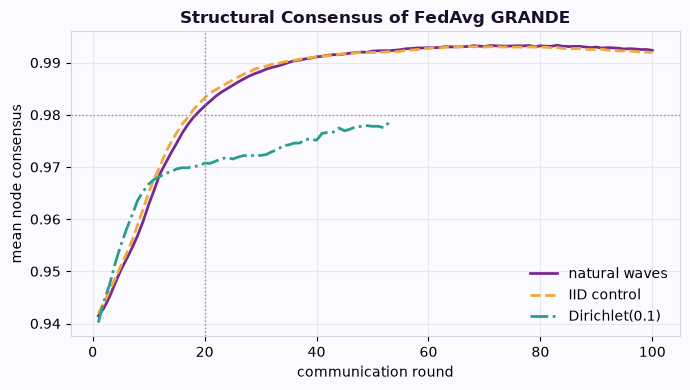

In [31]:
# fedavg grande under three partitions
het=pd.read_csv(art/"heterogeneity_summary.csv").set_index("partition")
het.index=["Natural","IID control","Dirichlet(0.1)"]
het=het.rename(columns={"fedavg_grande_oof_auc":"Pooled AUC","fedavg_grande_fold_auc":"Per-fold AUC",
                        "macro_f1_at_05":"Macro-F1 at 0.5","consensus_round20":"Consensus at round 20",
                        "best_round_mean":"Best round"})
het["Best round"]=het["Best round"].round(1)
display(het[["Pooled AUC","Per-fold AUC","Macro-F1 at 0.5","Consensus at round 20","Best round"]].round(3))

# plot mean node consensus per round
cons=pd.read_csv(art/"consensus_rounds.csv")
plt.figure(figsize=(7,4),facecolor=bg)
ax=plt.gca()
ax.set_facecolor(bg)
for p,cl,ls,lb in [("natural",c,"-","natural waves"),("iid",cb,"--","IID control"),("dirichlet0.1",ct,"-.","Dirichlet(0.1)")]:
    g=cons[cons.partition==p]
    ax.plot(g["round"],g["mean"],color=cl,ls=ls,lw=2,label=lb)
ax.axvline(20,color=cg,ls=":",lw=1)
ax.axhline(.98,color=cg,ls=":",lw=1)
ax.set_xlabel("communication round")
ax.set_ylabel("mean node consensus")
ax.set_title("Structural Consensus of FedAvg GRANDE",fontweight="bold",color=tx)
ax.grid(color=gr,lw=.8)
for s in ax.spines.values():
    s.set_color(sp)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

Natural client heterogeneity did not materially hurt FedAvg relative to the size-matched IID control on this dataset. Under extreme label skew the per-fold AUC stays at 0.827, but the pooled AUC and the macro-F1 at 0.5 collapse because the score level shifts from fold to fold: this is a calibration failure rather than a ranking failure. Lower consensus under label skew is an association between regimes, not a proven cause.

## Calibration and Personalization

Under Dirichlet(0.1) we compare the global model (P0), one logit intercept per client (P1), personalized leaves (P2), and personalized leaves and tree weights (P3). Within-client AUC measures ranking inside each client.

In [32]:
# calibration versus personalization
cal=pd.read_csv(art/"calibration_summary.csv").set_index("method")
cal=cal.rename(columns={"within_client_auc_per_fold_A1":"Within-client AUC","log_loss":"Log loss",
                        "ece10":"ECE","f1_05":"Macro-F1 at 0.5"})
cal.index=["P0: global model","P1: + client intercept","P2: + personal leaves","P3: + leaves and weights"]
display(cal[["Within-client AUC","Log loss","ECE","Macro-F1 at 0.5"]].round(3))

,Within-client AUC,Log loss,ECE,Macro-F1 at 0.5
P0: global model,0.770,0.542,0.212,0.455
P1: + client intercept,0.770,0.099,0.018,0.909
P2: + personal leaves,0.769,0.344,0.229,0.810
P3: + leaves and weights,0.768,0.339,0.227,0.820


One intercept per client fixes most of the calibration error (log loss 0.542 to 0.099, ECE 0.212 to 0.018) without changing the ranking inside a client. Personalizing the trees does not improve within-client AUC. The aggregate AUC of about 0.99 for P1 to P3 only reflects client identity under label skew and is not reported as discrimination.

## Communication Ablation

We count **conceptual tensor communication**: with $P_{\text{active}}$ communicated parameters, 4 bytes per value down and $b_{\text{up}}$ bytes per value up, one round with $K=21$ clients costs $B=K(4+b_{\text{up}})P_{\text{active}}$. For FedAvg GRANDE this is $21\cdot8\cdot809{,}984=136{,}077{,}312$ bytes. This is not measured network traffic.

In [33]:
# communication cost and auc of all configurations (natural partition)
com=pd.read_csv(art/"communication_summary.csv")
desc={"F0":"FedAvg baseline","C1":"64 trees","C2":"8-bit uplink","C3":"64 trees + 8-bit",
      "F1":"freeze feature logits @20","F2":"freeze structure @20","F3":"F2 + 8-bit uplink",
      "G1":"consensus gate (global)","G2":"consensus gate (node-wise)"}
nat=com[com.partition=="natural"].set_index("config")
iid=com[com.partition=="iid"].set_index("config")
tab=pd.DataFrame({"Configuration":[desc[k] for k in nat.index],"AUC":nat.auc,"ΔAUC":nat.d_auc,
                  "GB to best":nat.gb_to_best,"Saving (x)":nat.saving_x,"Saving IID (x)":iid.saving_x})
display(tab.round(4))

print("bytes per round, F0:",21*8*809984)
assert 21*8*809984==136077312
assert abs(nat.loc["F2","gb_to_best"]-3.0085)<1e-3 and abs(nat.loc["G1","gb_to_best"]-3.1591)<1e-3
assert abs(nat.loc["F0","gb_to_best"]-10.725)<1e-3 and abs(nat.loc["F2","d_auc"]+.0018)<1e-4

,Configuration,AUC,ΔAUC,GB to best,Saving (x),Saving IID (x)
config,,,,,,
F0,FedAvg baseline,0.8438,0.0000,10.7250,1.0000,1.0000
C1,64 trees,0.8341,-0.0096,2.1029,5.1000,4.5600
C2,8-bit uplink,0.8438,0.0000,7.1462,1.5008,1.5256
C3,64 trees + 8-bit,0.8352,-0.0086,1.2664,8.4692,7.9394
F1,freeze feature logits @20,0.8436,-0.0002,8.0557,1.3314,1.5489
F2,freeze structure @20,0.8420,-0.0018,3.0085,3.5649,4.1496
F3,F2 + 8-bit uplink,0.8419,-0.0018,2.9264,3.6649,4.2657
G1,consensus gate (global),0.8422,-0.0015,3.1591,3.3950,4.2118
G2,consensus gate (node-wise),0.8359,-0.0078,3.6278,2.9563,3.4245


bytes per round, F0: 136077312


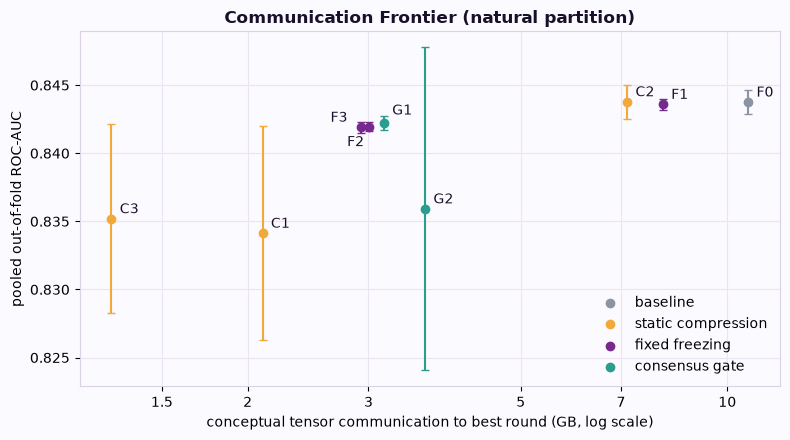

In [34]:
# plot auc against conceptual communication
plt.figure(figsize=(8,4.5),facecolor=bg)
ax=plt.gca()
ax.set_facecolor(bg)
grp={"F0":cg,"C1":cb,"C2":cb,"C3":cb,"F1":c,"F2":c,"F3":c,"G1":ct,"G2":ct}
for k,r in nat.iterrows():
    ax.errorbar(r.gb_to_best,r.auc,yerr=r.auc_sd,fmt="o",color=grp[k],capsize=3,ms=6)
    off={"F2":(-16,-14),"F3":(-22,4),"G1":(6,6)}.get(k,(6,4))
    ax.annotate(k,(r.gb_to_best,r.auc),textcoords="offset points",xytext=off,color=tx)
ax.set_xscale("log")
ax.set_xticks([1.5,2,3,5,7,10],["1.5","2","3","5","7","10"])
ax.minorticks_off()
ax.set_xlabel("conceptual tensor communication to best round (GB, log scale)")
ax.set_ylabel("pooled out-of-fold ROC-AUC")
ax.set_title("Communication Frontier (natural partition)",fontweight="bold",color=tx)
ax.grid(color=gr,lw=.8)
for s in ax.spines.values():
    s.set_color(sp)
for lb,cl in [("baseline",cg),("static compression",cb),("fixed freezing",c),("consensus gate",ct)]:
    ax.scatter([],[],color=cl,label=lb)
plt.legend(frameon=False,loc="lower right")
plt.tight_layout()
plt.show()

The 8-bit uplink costs no AUC but saves only 1.5 times. A 64-tree ensemble saves about 5 times but loses about 0.009 AUC. Freezing the structure after round 20 (F2) saves 3.6 to 4.1 times for about 0.002 AUC. The consensus gate G1 finds about the same freeze point automatically (round 20.4 ± 1.4) and matches F2; the node-wise gate G2 needs more communication.

## Comparison with State-of-the-Art Methods

Published SpeedDating results of four tuned models from the GRANDE paper (Marton et al., ICLR 2024, Tables 2 and 6) next to our models. Our values are the mean ± SD over the five grouped folds; the macro-F1 uses the validation-selected threshold.

In [35]:
# published values (grande paper, row-wise 5-fold cv, 250 tuning trials per model)
published=pd.DataFrame({
    "Model":["GRANDE [paper]","CatBoost [paper]","NODE [paper]","XGBoost [paper]"],
    "Macro-F1":["0.723 ± 0.013","0.718 ± 0.014","0.707 ± 0.015","0.704 ± 0.015"],
    "ROC-AUC":["0.859 ± 0.012","0.856 ± 0.014","0.853 ± 0.014","0.827 ± 0.017"],
    "Protocol":["row-wise, tuned"]*4
})

# our values from the saved predictions
ours=[]
for name,lb in [("Centralized GRANDE","Centralized GRANDE [ours]"),("FedAvg MLP (nat.)","FedAvg MLP [ours]"),
                ("FedAvg GRANDE (nat.)","FedAvg GRANDE [ours]"),("Local GRANDE (nat.)","Local-only GRANDE [ours]")]:
    ours.append([lb,f"{cv_mean.loc[name,'Macro-F1']:.3f} ± {cv_sd.loc[name,'Macro-F1']:.3f}",
                 f"{cv_mean.loc[name,'AUC']:.3f} ± {cv_sd.loc[name,'AUC']:.3f}","grouped, not tuned"])
sota=pd.concat([published,pd.DataFrame(ours,columns=published.columns)],ignore_index=True)
display(sota.set_index("Model"))
assert abs(cv_mean.loc["Centralized GRANDE","Macro-F1"]-.723)<.0005

,Macro-F1,ROC-AUC,Protocol
Model,,,
GRANDE [paper],0.723 ± 0.013,0.859 ± 0.012,"row-wise, tuned"
CatBoost [paper],0.718 ± 0.014,0.856 ± 0.014,"row-wise, tuned"
NODE [paper],0.707 ± 0.015,0.853 ± 0.014,"row-wise, tuned"
XGBoost [paper],0.704 ± 0.015,0.827 ± 0.017,"row-wise, tuned"
Centralized GRANDE [ours],0.723 ± 0.016,0.858 ± 0.017,"grouped, not tuned"
FedAvg MLP [ours],0.719 ± 0.021,0.851 ± 0.017,"grouped, not tuned"
FedAvg GRANDE [ours],0.705 ± 0.015,0.845 ± 0.022,"grouped, not tuned"
Local-only GRANDE [ours],0.633 ± 0.018,0.743 ± 0.017,"grouped, not tuned"


The published models use row-wise cross-validation and extensive tuning, while this project uses leakage-grouped cross-validation and no hyperparameter search. The values provide context, not a direct ranking.

## Conclusions

- Grouped evaluation removes the mirror-row leakage of row-wise CV (79.8% of test rows to 0).
- FedAvg GRANDE reaches a cross-validated ROC-AUC of 0.845, which is 98.5% of centralized GRANDE (0.858), and is about 0.10 better than isolated local training (0.743).
- Natural client heterogeneity did not materially hurt FedAvg relative to the size-matched IID control on this dataset.
- Extreme label skew is mainly a calibration problem: one intercept per client fixes it.
- The tree structure is 98% of the communicated parameters; freezing it after round 20 reduces conceptual communication 3.6 to 4.1 times for about 0.002 AUC, and the global consensus gate finds about the same freeze point automatically.

**Limitations:** one dataset; three seeds on fixed folds; no hyperparameter search; conceptual communication instead of measured traffic; no privacy mechanism.

In [36]:
# total run time of this notebook
print("notebook run time (s):",round(time.perf_counter()-t_start,1))

notebook run time (s): 4.3
